# So sánh model của Trí và của Bảo

**Đồ án CV nâng cao · 20/11/2026**

Hai thành viên train B1/B2 song song với cùng cấu hình (fine-tune toàn bộ InceptionResnetV1, 5 epoch, batch 8, AdamW 1e-5/1e-3, seed 20261028, 1.600 người DigiFace). Khác nhau ở code và máy:

| | Bảo | Trí |
|---|---|---|
| Code | `huan_luyen/Train_full_B1_B2.ipynb` | `model_tri/training/train.py` |
| Máy | RTX 4060 Laptop, Windows | GPU server Linux |
| Che của B2 | 4 vùng, màu xám ngẫu nhiên (thuật toán augmentation của nhóm) | 4 vùng, màu đen, tọa độ riêng |
| Epoch được chọn | B1: 3, B2: 4 | B1: 4, B2: 5 |

Notebook chấm cả năm model (B0, B1/B2 của Bảo, B1/B2 của Trí) bằng **cùng một evaluator** trên DigiFace validation, DigiFace test, ROF và MFR2, để trả lời: hai lượt train có ra kết quả giống nhau không, và kết luận của bước 7 (fine-tune trên ảnh tổng hợp làm kém trên ảnh thật) có đúng với model của Trí không.

## 1. Nạp model và khóa ngưỡng

Ngưỡng của mỗi model chọn trên DigiFace validation theo quy tắc chung (FPIR ≤ 5%, DIR lớn nhất, hòa lấy ngưỡng cao hơn). Ngưỡng của B0 và hai model của Bảo đã khóa ở bước 7 (notebook kiểm lại: tính lại ra cùng ngưỡng với hai model của Bảo; với B0 lệch ~1e-4 do batch size khác bước 5, nên dùng ngưỡng đã khóa); ngưỡng của hai model Trí được tính ở mục 2 và ghi vào `khoa_nguong_model_Tri.json` trước khi notebook mở ảnh test.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from concurrent.futures import ThreadPoolExecutor
import os, sys, json, hashlib, time, gc, platform, warnings
warnings.filterwarnings('ignore', message='IProgress not found')
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import torch
from facenet_pytorch.models.mtcnn import fixed_image_standardization


def find_root():
    options = [Path(os.environ['CV_PROJECT_ROOT'])] if os.environ.get('CV_PROJECT_ROOT') else []
    options += [Path.cwd(), *Path.cwd().parents]
    for p in options:
        if (p / 'ban_giao_nhom/model_tri/So_sanh_model_Tri_va_Bao.ipynb').is_file():
            return p.resolve()
    raise FileNotFoundError('Mở notebook trong thư mục dự án hoặc đặt CV_PROJECT_ROOT')


ROOT = find_root()
HERE = ROOT / 'ban_giao_nhom/model_tri'
OUT = HERE / 'notebook_outputs'; TAB, FIG, CACHE = OUT / 'tables', OUT / 'figures', OUT / 'cache'
for p in [OUT, TAB, FIG, CACHE]:
    p.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT / 'ban_giao_nhom/huan_luyen'))
from tai_model import load_encoder
SEED = 20261028
DEVICE = 'cuda:0' if torch.cuda.is_available() else 'cpu'
torch.backends.cudnn.benchmark = False; torch.backends.cudnn.deterministic = True
PROT = ROOT / 'ban_giao_nhom/protocol/notebook_outputs/tables'
START = time.perf_counter()


def sha(p):
    h = hashlib.sha256()
    with Path(p).open('rb') as f:
        for b in iter(lambda: f.read(2**20), b''):
            h.update(b)
    return h.hexdigest()


def save(d, name):
    d.to_csv(TAB / (name + '.csv'), index=False, encoding='utf-8-sig', float_format='%.17g'); return d


def vn(x, d=2):
    return f'{x:,.{d}f}'.replace(',', '_').replace('.', ',').replace('_', '.')


def pct(x):
    return vn(100 * x) + '%'


def finish(fig, name):
    for ext in ['png', 'svg']:
        fig.savefig(FIG / (name + '.' + ext), bbox_inches='tight', dpi=160)
    display(fig); plt.close(fig)


plt.rcParams.update({'font.family': 'Arial', 'figure.dpi': 110, 'axes.unicode_minus': False,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e4e3df', 'grid.linewidth': .6})
MODELS = ['B0', 'B1_Bao', 'B2_Bao', 'B1_Tri', 'B2_Tri']
COLORS = {'B0': '#8a8984', 'B1_Bao': '#2a78d6', 'B2_Bao': '#eb6834', 'B1_Tri': '#86b6ef', 'B2_Tri': '#f4a582'}
FILES = {'B1_Bao': ROOT / 'ban_giao_nhom/huan_luyen/checkpoints_full/B1_best_encoder.pt',
         'B2_Bao': ROOT / 'ban_giao_nhom/huan_luyen/checkpoints_full/B2_best_encoder.pt',
         'B1_Tri': HERE / 'checkpoints/B1_Tri_encoder.pt', 'B2_Tri': HERE / 'checkpoints/B2_Tri_encoder.pt'}
LOCK7 = json.loads((ROOT / 'ban_giao_nhom/danh_gia_test/khoa_cau_hinh_buoc7.json').read_text(encoding='utf-8'))
for b in ['B1', 'B2']:
    assert sha(FILES[f'{b}_Bao']) == LOCK7['models'][b]['sha256'], f'Model {b} của Bảo khác file đã khóa ở bước 7'
TRI_REPORTED = {}
for b in ['B1', 'B2']:
    info = torch.load(FILES[f'{b}_Tri'], map_location='cpu', weights_only=True)
    TRI_REPORTED[f'{b}_Tri'] = {'epoch': info['epoch'], 'DIR': info['metrics']['DIR'], 'threshold': info['metrics']['threshold'],
                                'correct': info['metrics']['known_correct_accepted'], 'unknown_accepted': info['metrics']['unknown_accepted']}
    del info
display(pd.DataFrame([{'model': m, 'file': (FILES[m].relative_to(ROOT).as_posix() if m in FILES else 'pretrained VGGFace2'),
                       'SHA-256': sha(FILES[m])[:16] + '…' if m in FILES else '–'} for m in MODELS]))
display(Markdown('Kết quả Trí tự báo (từ checkpoint): ' + '; '.join(
    f"{m} epoch {r['epoch']}: DIR {pct(r['DIR'])}, ngưỡng {r['threshold']:.4f}" for m, r in TRI_REPORTED.items())))

,model,file,SHA-256
0,B0,pretrained VGGFace2,–
1,B1_Bao,ban_giao_nhom/huan_luyen/checkpoints_full/B1_b...,c68f5a1e9aa92644…
2,B2_Bao,ban_giao_nhom/huan_luyen/checkpoints_full/B2_b...,b57e1c7309cb580e…
3,B1_Tri,ban_giao_nhom/model_tri/checkpoints/B1_Tri_enc...,1f89215b1c41bcb6…
4,B2_Tri,ban_giao_nhom/model_tri/checkpoints/B2_Tri_enc...,2806f8f1933130db…


Kết quả Trí tự báo (từ checkpoint): B1_Tri epoch 4: DIR 94,78%, ngưỡng 0.5493; B2_Tri epoch 5: DIR 94,54%, ngưỡng 0.5737

In [2]:
def make_spec(image_id, epoch, partition, force=False):
    seed=int(hashlib.sha256(f"{AUG['seed']}|{partition}|{epoch}|{image_id}".encode()).hexdigest()[:16],16)
    rng=np.random.default_rng(seed)
    applied=bool(force or rng.random()<AUG['train_probability'])
    kind=AUG['kinds'][int(rng.integers(len(AUG['kinds'])))] if applied else 'none'
    box=[0,0,0,0];fill=0
    if applied:
        box=np.array(AUG['boxes'][kind],dtype=int)+rng.integers(-4,5,size=4)
        box=np.clip(box,0,160).tolist()
        fill=int(rng.choice(AUG['fill_values']))
    area=max(0,box[2]-box[0])*max(0,box[3]-box[1])
    return {'image_id':image_id,'epoch':int(epoch),'partition':partition,'seed':str(seed),
            'applied':applied,'kind':kind,'x1':box[0],'y1':box[1],'x2':box[2],'y2':box[3],
            'fill_gray':fill,'mask_pixels':area,'frame_pixels':160*160,
            'mask_fraction_frame':area/(160*160),
            'variant_id':'VAR_'+hashlib.sha256(f'{image_id}|{seed}|{kind}|{box}|{fill}'.encode()).hexdigest()[:24]}

def apply_spec(pixels,spec):
    if pixels.dtype!=np.uint8 or pixels.shape!=(160,160,3):raise ValueError('Expected uint8 RGB160')
    mask=np.zeros((160,160),dtype=np.uint8)
    if bool(spec['applied']):mask[int(spec['y1']):int(spec['y2']),int(spec['x1']):int(spec['x2'])]=1
    if int(mask.sum())!=int(spec['mask_pixels']):raise ValueError('Mask area does not match metadata')
    result=pixels.copy();result[mask.astype(bool)]=int(spec['fill_gray'])
    return result,mask

## 2. DigiFace validation: tái lập số liệu của Trí

Đọc ảnh giống lúc train (EXIF, RGB, resize bilinear 160, chuẩn hóa một lần). Query che dùng đúng 7.700 biến thể cố định của notebook augmentation, giống bước 6. Nếu evaluator của nhóm ra cùng số query đúng (3.507 cho B1, 3.498 cho B2) như Trí tự báo thì hai bên đo cùng một thứ.

In [3]:
R = pd.read_csv(PROT / '05_image_roles_draft.csv', dtype=str, keep_default_na=False)
aug = json.loads((ROOT / 'ban_giao_nhom/augmentation/notebook_outputs/augmentation_pilot_contract.json').read_text(encoding='utf-8'))
nb_cells = json.loads((HERE / 'So_sanh_model_Tri_va_Bao.ipynb').read_text(encoding='utf-8'))['cells']
common_src = next(''.join(c['source']) for c in nb_cells if c['cell_type'] == 'code' and ''.join(c['source']).startswith('def make_spec'))
assert hashlib.sha256(common_src.encode()).hexdigest() == aug['implementation_sha256']
AUG = aug['augmentation']
VS = pd.read_csv(ROOT / 'ban_giao_nhom/augmentation/notebook_outputs/tables/02_validation_query_variant_specs.csv', dtype={'seed': str})
TS7 = pd.read_csv(ROOT / 'ban_giao_nhom/danh_gia_test/notebook_outputs/tables/01_digiface_test_query_occlusion_specs.csv', dtype={'seed': str})
V = R[R.partition.eq('val')].sort_values('image_id').reset_index(drop=True)
T = R[R.partition.eq('test')].sort_values('image_id').reset_index(drop=True)
RO = pd.read_csv(PROT / '07_rof_image_roles_draft.csv', dtype=str, keep_default_na=False)
RO = RO[RO.role.isin(['gallery', 'known_query', 'unknown_query'])].sort_values('image_id').reset_index(drop=True)
EX = pd.read_csv(PROT / '07_external_image_roles_draft.csv', dtype=str, keep_default_na=False)
MF = EX[EX.source.eq('MFR2')].sort_values('image_id').reset_index(drop=True)
MF['rel'] = MF.path.str.replace('data/raw/mfr2/mfr2/', '', regex=False)
PAIRS = pd.read_csv(PROT / '08_mfr2_official_pairs_preserved.csv', dtype=str, keep_default_na=False)
PAIRS['same'] = PAIRS.same_person.eq('True')
for name, f in [('digiface_roles', '05_image_roles_draft.csv'), ('rof_roles', '07_rof_image_roles_draft.csv'),
                ('external_roles', '07_external_image_roles_draft.csv'), ('mfr2_pairs', '08_mfr2_official_pairs_preserved.csv')]:
    assert sha(PROT / f) == LOCK7['inputs_sha256'][name]


def rgb160(row):
    with Image.open(ROOT / row.path) as source:
        im = ImageOps.exif_transpose(source)
        if 'A' in im.getbands():
            rgba = im.convert('RGBA')
            if (np.asarray(rgba.getchannel('A')) < 255).any():
                im = Image.alpha_composite(Image.new('RGBA', rgba.size, (255, 255, 255, 255)), rgba)
        return np.asarray(im.convert('RGB').resize((160, 160), Image.Resampling.BILINEAR), dtype=np.uint8).copy()


def load_pixels(frame, name):
    path = CACHE / f'pix_{name}.npy'
    if path.exists():
        arr = np.load(path)
        if len(arr) == len(frame):
            return arr
    with ThreadPoolExecutor(max_workers=6) as pool:
        ok = list(pool.map(lambda r: sha(ROOT / r.path) == r.sha256, frame.itertuples()))
        assert all(ok), f'{name}: có ảnh khác SHA trong protocol'
        arr = np.stack(list(pool.map(rgb160, frame.itertuples())))
    np.save(path, arr); return arr


def embed(model, pixels, batch=256):
    out = []
    with torch.inference_mode():
        for s in range(0, len(pixels), batch):
            x = fixed_image_standardization(torch.from_numpy(np.array(pixels[s:s + batch], copy=True)).permute(0, 3, 1, 2).float())
            out.append(model(x.to(DEVICE)).cpu().numpy().astype(np.float32))
    return np.concatenate(out)


def occluded(frame, pixels, specs):
    by_id = {r['image_id']: r for r in specs.to_dict('records')}
    q = frame.role.isin(['known_query', 'unknown_query']).to_numpy()
    out = pixels.copy()
    for i in np.flatnonzero(q):
        out[i] = apply_spec(out[i], by_id[frame.image_id.iloc[i]])[0]
    return out


PIX = {'val': load_pixels(V, 'val')}
PIX['val_occ'] = occluded(V, PIX['val'], VS)


def open_set(frame, emb, threshold, valid=None):
    valid = np.ones(len(frame), bool) if valid is None else valid
    g = frame.role.eq('gallery').to_numpy() & valid
    persons = sorted(frame.loc[frame.role.eq('gallery'), 'canonical_identity'].unique())
    T_, enrolled = [], []
    for p in persons:
        idx = np.flatnonzero(g & frame.canonical_identity.eq(p).to_numpy())
        if len(idx):
            t = emb[idx].mean(axis=0); T_.append(t / np.linalg.norm(t)); enrolled.append(p)
    T_ = np.stack(T_).astype(np.float32)
    qm = frame.role.isin(['known_query', 'unknown_query']).to_numpy()
    q = frame.loc[qm, ['image_id', 'canonical_identity', 'role', 'condition']].reset_index(drop=True)
    sim = emb[qm] @ T_.T; top = sim.argmax(axis=1)
    q['is_known'] = q.role.eq('known_query')
    q['top_identity'] = np.asarray(enrolled)[top]
    q['top_score'] = sim[np.arange(len(q)), top].astype(np.float32)
    q['top1_correct'] = q.is_known & q.top_identity.eq(q.canonical_identity)
    if threshold is not None:
        q['accepted'] = q.top_score.to_numpy(np.float32) >= np.float32(threshold)
        q['correct_accepted'] = q.accepted & q.top1_correct
        q['unknown_accepted'] = q.accepted & ~q.is_known
    return q


def choose_threshold(q):
    known = q.is_known.to_numpy(); correct = q.top1_correct.to_numpy(); s = q.top_score.to_numpy(np.float32)
    cand = np.r_[np.unique(s).astype(np.float64), np.inf]
    hit = np.sort(s[known & correct]); unk = np.sort(s[~known])
    DIR = (len(hit) - np.searchsorted(hit, cand, side='left')) / known.sum()
    FPIR = (len(unk) - np.searchsorted(unk, cand, side='left')) / (~known).sum()
    ok = FPIR <= .05
    return float(cand[ok & (DIR == DIR[ok].max())].max())


def rates(q):
    k, u = q.is_known, ~q.is_known
    return {'DIR': float(q.correct_accepted[k].mean()), 'FPIR': float(q.unknown_accepted[u].mean()) if u.any() else np.nan,
            'Rank-1': float(q.top1_correct[k].mean()), 'đúng': int(q.correct_accepted[k].sum()), 'người lạ nhận nhầm': int(q.unknown_accepted[u].sum())}


ENCODERS, EMB, THRESHOLDS, VAL_Q = {}, {}, {}, {}
val_rows = []
for m in MODELS:
    model = load_encoder('B0', device=DEVICE) if m == 'B0' else load_encoder(m, device=DEVICE, checkpoint=FILES[m])
    EMB[m] = {'val': embed(model, PIX['val']), 'val_occ': embed(model, PIX['val_occ'])}
    q0 = open_set(V, EMB[m]['val'], None)
    THRESHOLDS[m] = choose_threshold(q0)
    if m == 'B0':
        # Bước 5 tính embedding B0 với batch khác; đổi batch làm embedding lệch ~1e-4 và ngưỡng lệch theo.
        # B0 dùng đúng ngưỡng đã khóa ở bước 7 (bước 7 cũng chấm B0 như vậy).
        B0_RECOMPUTED = THRESHOLDS[m]; THRESHOLDS[m] = float(LOCK7['models']['B0']['validation_threshold'])
    qb = open_set(V, EMB[m]['val'], THRESHOLDS[m])
    emb_occ = EMB[m]['val'].copy(); qm = V.role.isin(['known_query', 'unknown_query']).to_numpy()
    emb_occ[qm] = EMB[m]['val_occ'][qm]
    qo = open_set(V, emb_occ, THRESHOLDS[m])
    VAL_Q[m] = (qb, qo)
    rb, ro = rates(qb), rates(qo)
    val_rows.append({'model': m, 'ngưỡng': THRESHOLDS[m], 'DIR nền': rb['DIR'], 'FPIR nền': rb['FPIR'], 'Rank-1 nền': rb['Rank-1'],
                     'đúng (nền)': rb['đúng'], 'DIR che': ro['DIR'], 'FPIR che': ro['FPIR']})
    ENCODERS[m] = model
VAL_RES = save(pd.DataFrame(val_rows), '01_validation_all_models')
for b in ['B1', 'B2']:
    assert abs(THRESHOLDS[f'{b}_Bao'] - LOCK7['models'][b]['validation_threshold']) < 1e-6, f'{b}_Bao khác ngưỡng bước 6–7'
assert abs(B0_RECOMPUTED - THRESHOLDS['B0']) < 1e-3
display(Markdown(f"B0: ngưỡng tính lại {B0_RECOMPUTED:.6f}, ngưỡng đã khóa {THRESHOLDS['B0']:.6f} (lệch do batch size); dùng ngưỡng đã khóa."))
repro = []
for m, r in TRI_REPORTED.items():
    row = VAL_RES.set_index('model').loc[m]
    repro.append({'model': m, 'đúng (Trí báo)': r['correct'], 'đúng (notebook này)': int(row['đúng (nền)']),
                  'ngưỡng (Trí báo)': round(r['threshold'], 6), 'ngưỡng (notebook này)': round(THRESHOLDS[m], 6)})
REPRO = save(pd.DataFrame(repro), '01_reproduce_tri_validation')
show = VAL_RES.copy()
for c in ['DIR nền', 'FPIR nền', 'Rank-1 nền', 'DIR che', 'FPIR che']:
    show[c] = (100 * show[c]).round(2)
display(show); display(REPRO)

B0: ngưỡng tính lại 0.693032, ngưỡng đã khóa 0.693074 (lệch do batch size); dùng ngưỡng đã khóa.

,model,ngưỡng,DIR nền,FPIR nền,Rank-1 nền,đúng (nền),DIR che,FPIR che
0,B0,0.693074,57.08,5.00,82.86,2112,22.73,2.75
1,B1_Bao,0.531435,93.49,4.85,97.00,3459,56.51,4.32
2,B2_Bao,0.525244,93.49,4.95,97.08,3459,79.62,4.70
3,B1_Tri,0.549414,94.76,4.92,97.16,3506,62.49,6.12
4,B2_Tri,0.573418,94.57,5.00,97.11,3499,74.95,5.68


,model,đúng (Trí báo),đúng (notebook này),ngưỡng (Trí báo),ngưỡng (notebook này)
0,B1_Tri,3507,3506,0.549332,0.549414
1,B2_Tri,3498,3499,0.573716,0.573418


## 3. Khóa ngưỡng của model Trí, rồi chấm test

Ngưỡng hai model Trí vừa tính trên validation được ghi vào file khóa. Từ đây không có tham số nào được chọn theo test. DigiFace test dùng đúng 7.700 query che cố định của bước 7; ROF dùng cách A (resize crop có sẵn) như cách chính của bước 7; MFR2 là 848 cặp chính thức.

In [4]:
LOCK = {'version': 'tri_comparison_v1', 'thresholds': THRESHOLDS,
        'files_sha256': {m: sha(f) for m, f in FILES.items()}, 'rule': 'giống bước 7: FPIR <= 5% trên DigiFace val, DIR lớn nhất, hòa lấy ngưỡng cao hơn',
        'step7_lock_sha256': sha(ROOT / 'ban_giao_nhom/danh_gia_test/khoa_cau_hinh_buoc7.json')}
LOCK_PATH = HERE / 'khoa_nguong_model_Tri.json'
if LOCK_PATH.exists():
    old = json.loads(LOCK_PATH.read_text(encoding='utf-8'))
    assert {k: v for k, v in old.items() if k != 'locked_at_utc'} == json.loads(json.dumps(LOCK)), 'Ngưỡng/model khác file khóa'
    LOCK_STATUS = 'file khóa có sẵn, khớp'
else:
    LOCK_PATH.write_text(json.dumps({**LOCK, 'locked_at_utc': datetime.now(timezone.utc).isoformat()}, ensure_ascii=False, indent=2), encoding='utf-8')
    LOCK_STATUS = 'vừa ghi file khóa'
display(Markdown(f'**{LOCK_STATUS}:** `{LOCK_PATH.name}`'))

PIX['test'] = load_pixels(T, 'test'); PIX['test_occ'] = occluded(T, PIX['test'], TS7)
PIX['rof'] = load_pixels(RO, 'rof'); PIX['mfr2'] = load_pixels(MF, 'mfr2')
for m in MODELS:
    for k in ['test', 'test_occ', 'rof', 'mfr2']:
        EMB[m][k] = embed(ENCODERS[m], PIX[k])
del ENCODERS; gc.collect(); torch.cuda.empty_cache() if DEVICE.startswith('cuda') else None


def det_dir(q, cond=None):
    known = q.is_known.to_numpy(); correct = q.top1_correct.to_numpy(); s = q.top_score.to_numpy(np.float32)
    cand = np.r_[np.unique(s).astype(np.float64), np.inf]
    hit = np.sort(s[known & correct]); unk = np.sort(s[~known])
    FPIR = (len(unk) - np.searchsorted(unk, cand, side='left')) / (~known).sum()
    DIR = (len(hit) - np.searchsorted(hit, cand, side='left')) / known.sum()
    ok = FPIR <= .05; t = float(cand[ok & (DIR == DIR[ok].max())].max())
    sel = q if cond is None else q[q.condition.eq(cond)]
    return float(((sel.top_score.to_numpy(np.float32) >= np.float32(t)) & sel.top1_correct.to_numpy())[sel.is_known.to_numpy()].mean())


rows, QS = [], {}
qmT = T.role.isin(['known_query', 'unknown_query']).to_numpy()
for m in MODELS:
    qb = open_set(T, EMB[m]['test'], THRESHOLDS[m])
    e = EMB[m]['test'].copy(); e[qmT] = EMB[m]['test_occ'][qmT]
    qo = open_set(T, e, THRESHOLDS[m])
    qr = open_set(RO, EMB[m]['rof'], THRESHOLDS[m])
    QS[m] = {'test': qb, 'test_occ': qo, 'rof': qr}
    rb, ro_, rr = rates(qb), rates(qo), rates(qr)
    s = (EMB[m]['mfr2'][PAIRS.a.map(dict(zip(MF.rel, range(len(MF))))).to_numpy()] *
         EMB[m]['mfr2'][PAIRS.b.map(dict(zip(MF.rel, range(len(MF))))).to_numpy()]).sum(axis=1)
    y = PAIRS.same.to_numpy()
    order = np.argsort(s); ranks = np.empty(len(s)); ranks[order] = np.arange(1, len(s) + 1)
    auc = (ranks[y].sum() - y.sum() * (y.sum() + 1) / 2) / (y.sum() * (~y).sum())
    rows.append({'model': m, 'DigiFace test DIR nền': rb['DIR'], 'DigiFace test FPIR nền': rb['FPIR'], 'DigiFace test DIR che': ro_['DIR'],
                 'ROF Rank-1': rr['Rank-1'], 'ROF Rank-1 khẩu trang': float(qr[qr.is_known & qr.condition.eq('masked')].top1_correct.mean()),
                 'ROF Rank-1 kính râm': float(qr[qr.is_known & qr.condition.eq('sunglasses')].top1_correct.mean()),
                 'ROF DIR @FPIR5% trên ROF': det_dir(qr), 'ROF FPIR tại ngưỡng val': rr['FPIR'], 'MFR2 AUC': float(auc)})
TEST_RES = save(pd.DataFrame(rows), '02_test_all_models')
show = TEST_RES.copy()
for c in show.columns[1:]:
    show[c] = show[c].round(4) if c == 'MFR2 AUC' else (100 * show[c]).round(2)
display(show.set_index('model').T)

**vừa ghi file khóa:** `khoa_nguong_model_Tri.json`

model,B0,B1_Bao,B2_Bao,B1_Tri,B2_Tri
DigiFace test DIR nền,62.9200,95.3800,95.2400,96.9200,95.8400
DigiFace test FPIR nền,4.9000,6.1000,8.7200,8.2000,7.2000
DigiFace test DIR che,25.4600,58.9500,81.0500,63.8100,75.0000
ROF Rank-1,92.8000,72.2300,67.1600,68.9300,60.3100
ROF Rank-1 khẩu trang,80.3400,34.8300,36.5200,30.9000,30.3400
ROF Rank-1 kính râm,84.9900,49.3700,43.0200,45.3200,34.6400
ROF DIR @FPIR5% trên ROF,77.7400,40.5500,32.9100,34.6500,27.3500
ROF FPIR tại ngưỡng val,0.0900,89.6400,93.4600,93.4600,92.9000
MFR2 AUC,0.9908,0.9349,0.9441,0.9146,0.9415


## 4. Hai lượt train có khác nhau thật không?

Hiệu Trí − Bảo cho cùng loại model, kèm CI 95% bootstrap theo người (ghép cặp: cùng mẫu người cho cả hai model, 2.000 lần). CI chứa 0 thì không phân biệt được hai lượt train.

,so sánh,chỉ số,điểm,ci95 thấp,ci95 cao
0,B1: Trí − Bảo,"DigiFace test, DIR nền",1.54,0.57,2.65
1,B1: Trí − Bảo,"DigiFace test, DIR che",4.86,2.70,6.86
2,B1: Trí − Bảo,"ROF, Rank-1",-3.30,-5.16,-1.50
3,B1_Tri − B0,"ROF, Rank-1",-23.87,-26.87,-20.98
4,B2: Trí − Bảo,"DigiFace test, DIR nền",0.59,-0.81,1.95
5,B2: Trí − Bảo,"DigiFace test, DIR che",-6.05,-7.87,-4.16
6,B2: Trí − Bảo,"ROF, Rank-1",-6.86,-8.73,-4.83
7,B2_Tri − B0,"ROF, Rank-1",-32.49,-35.99,-29.18


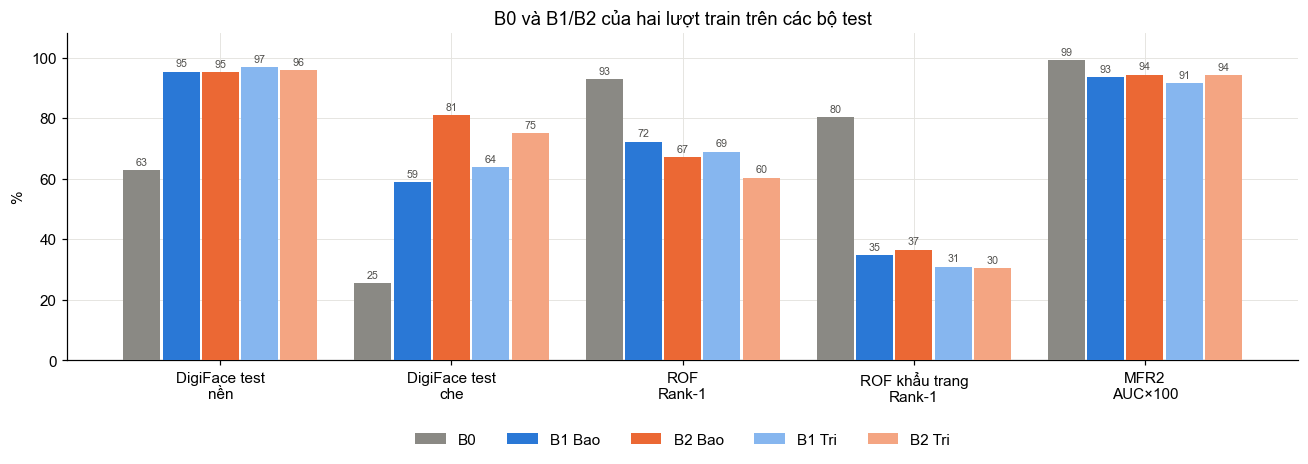

In [5]:
def boot_diff(qa, qb, col, frame_known_ids, reps=2000):
    def arr(q):
        return q[q.is_known].groupby('canonical_identity').agg(h=(col, 'sum'), n=('image_id', 'size')).reindex(frame_known_ids, fill_value=0).to_numpy(float)
    a, b = arr(qa), arr(qb)
    rng = np.random.default_rng(SEED); d = []
    for _ in range(reps):
        i = rng.integers(0, len(frame_known_ids), len(frame_known_ids))
        d.append(a[i, 0].sum() / a[i, 1].sum() - b[i, 0].sum() / b[i, 1].sum())
    point = a[:, 0].sum() / a[:, 1].sum() - b[:, 0].sum() / b[:, 1].sum()
    lo, hi = np.quantile(d, [.025, .975])
    return point, lo, hi


rows = []
known_T = sorted(T[T.role.eq('known_query')].canonical_identity.unique())
known_R = sorted(RO[RO.role.eq('known_query')].canonical_identity.unique())
for b in ['B1', 'B2']:
    for label, key, col, ids in [('DigiFace test, DIR nền', 'test', 'correct_accepted', known_T),
                                 ('DigiFace test, DIR che', 'test_occ', 'correct_accepted', known_T),
                                 ('ROF, Rank-1', 'rof', 'top1_correct', known_R)]:
        p, lo, hi = boot_diff(QS[f'{b}_Tri'][key], QS[f'{b}_Bao'][key], col, ids)
        rows.append({'so sánh': f'{b}: Trí − Bảo', 'chỉ số': label, 'điểm': p, 'ci95 thấp': lo, 'ci95 cao': hi})
    for label, key, col, ids in [('ROF, Rank-1', 'rof', 'top1_correct', known_R)]:
        p, lo, hi = boot_diff(QS[f'{b}_Tri'][key], QS['B0'][key], col, ids)
        rows.append({'so sánh': f'{b}_Tri − B0', 'chỉ số': label, 'điểm': p, 'ci95 thấp': lo, 'ci95 cao': hi})
DIFF = save(pd.DataFrame(rows), '03_tri_minus_bao_CI')
display(DIFF.assign(**{c: lambda d, c=c: (100 * d[c]).round(2) for c in ['điểm', 'ci95 thấp', 'ci95 cao']}))

labels = ['DigiFace test\nnền', 'DigiFace test\nche', 'ROF\nRank-1', 'ROF khẩu trang\nRank-1', 'MFR2\nAUC×100']
cols = ['DigiFace test DIR nền', 'DigiFace test DIR che', 'ROF Rank-1', 'ROF Rank-1 khẩu trang', 'MFR2 AUC']
fig, ax = plt.subplots(figsize=(12, 4.4)); w = .16
for i, m in enumerate(MODELS):
    vals = [100 * TEST_RES.set_index('model').loc[m, c] for c in cols]
    bars = ax.bar(np.arange(len(cols)) + (i - 2) * (w + .01), vals, w, color=COLORS[m], label=m.replace('_', ' '), zorder=3)
    ax.bar_label(bars, fmt='%.0f', fontsize=7, padding=2, color='#52514e')
ax.set_xticks(np.arange(len(cols)), labels); ax.set_ylim(0, 108)
ax.set(ylabel='%', title='B0 và B1/B2 của hai lượt train trên các bộ test')
ax.legend(frameon=False, ncols=5, loc='upper center', bbox_to_anchor=(.5, -.18)); fig.tight_layout(); finish(fig, '01_tri_vs_bao')

In [6]:
t = TEST_RES.set_index('model'); d = DIFF.set_index(['so sánh', 'chỉ số'])
fmt = lambda r: f"{100 * r['điểm']:+.2f} điểm, CI 95% [{100 * r['ci95 thấp']:+.2f}; {100 * r['ci95 cao']:+.2f}]".replace('.', ',')
rp = REPRO.set_index('model')
summary = {'checks': 'PASS', 'thresholds': THRESHOLDS, 'lock_status': LOCK_STATUS, 'validation': VAL_RES.to_dict('records'),
           'reproduce_tri': REPRO.to_dict('records'), 'test': TEST_RES.to_dict('records'), 'diff': DIFF.to_dict('records'),
           'device': DEVICE, 'executed_at_utc': datetime.now(timezone.utc).isoformat(), 'elapsed_seconds': time.perf_counter() - START}
(OUT / 'execution_summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2, default=str), encoding='utf-8')
display(Markdown(f"""## 5. Kết luận

- **Tái lập số liệu của Trí:** trên DigiFace validation, evaluator của nhóm cho B1_Tri {rp.loc['B1_Tri', 'đúng (notebook này)']} query đúng (Trí báo {rp.loc['B1_Tri', 'đúng (Trí báo)']}), B2_Tri {rp.loc['B2_Tri', 'đúng (notebook này)']} (Trí báo {rp.loc['B2_Tri', 'đúng (Trí báo)']}).
- **DigiFace test, ảnh nền:** B1 Bảo {pct(t.loc['B1_Bao', 'DigiFace test DIR nền'])} / Trí {pct(t.loc['B1_Tri', 'DigiFace test DIR nền'])}; B2 Bảo {pct(t.loc['B2_Bao', 'DigiFace test DIR nền'])} / Trí {pct(t.loc['B2_Tri', 'DigiFace test DIR nền'])}.
- **DigiFace test, query che:** B1 Bảo {pct(t.loc['B1_Bao', 'DigiFace test DIR che'])} / Trí {pct(t.loc['B1_Tri', 'DigiFace test DIR che'])}; B2 Bảo {pct(t.loc['B2_Bao', 'DigiFace test DIR che'])} / Trí {pct(t.loc['B2_Tri', 'DigiFace test DIR che'])}. B2: Trí − Bảo = {fmt(d.loc[('B2: Trí − Bảo', 'DigiFace test, DIR che')])}.
- **ROF (ảnh thật), Rank-1:** B0 {pct(t.loc['B0', 'ROF Rank-1'])}; B1 Bảo {pct(t.loc['B1_Bao', 'ROF Rank-1'])} / Trí {pct(t.loc['B1_Tri', 'ROF Rank-1'])}; B2 Bảo {pct(t.loc['B2_Bao', 'ROF Rank-1'])} / Trí {pct(t.loc['B2_Tri', 'ROF Rank-1'])}. B1_Tri − B0 = {fmt(d.loc[('B1_Tri − B0', 'ROF, Rank-1')])}; B2_Tri − B0 = {fmt(d.loc[('B2_Tri − B0', 'ROF, Rank-1')])}.
- **MFR2 AUC:** B0 {t.loc['B0', 'MFR2 AUC']:.4f}; B1 Bảo {t.loc['B1_Bao', 'MFR2 AUC']:.4f} / Trí {t.loc['B1_Tri', 'MFR2 AUC']:.4f}; B2 Bảo {t.loc['B2_Bao', 'MFR2 AUC']:.4f} / Trí {t.loc['B2_Tri', 'MFR2 AUC']:.4f}.

Ngưỡng hai model Trí khóa trong `{LOCK_PATH.name}` trước khi chấm test. Mỗi lượt train là một seed; chênh lệch giữa hai lượt gồm cả khác biệt code, cách che và máy.
"""))

## 5. Kết luận

- **Tái lập số liệu của Trí:** trên DigiFace validation, evaluator của nhóm cho B1_Tri 3506 query đúng (Trí báo 3507), B2_Tri 3499 (Trí báo 3498).
- **DigiFace test, ảnh nền:** B1 Bảo 95,38% / Trí 96,92%; B2 Bảo 95,24% / Trí 95,84%.
- **DigiFace test, query che:** B1 Bảo 58,95% / Trí 63,81%; B2 Bảo 81,05% / Trí 75,00%. B2: Trí − Bảo = -6,05 điểm, CI 95% [-7,87; -4,16].
- **ROF (ảnh thật), Rank-1:** B0 92,80%; B1 Bảo 72,23% / Trí 68,93%; B2 Bảo 67,16% / Trí 60,31%. B1_Tri − B0 = -23,87 điểm, CI 95% [-26,87; -20,98]; B2_Tri − B0 = -32,49 điểm, CI 95% [-35,99; -29,18].
- **MFR2 AUC:** B0 0.9908; B1 Bảo 0.9349 / Trí 0.9146; B2 Bảo 0.9441 / Trí 0.9415.

Ngưỡng hai model Trí khóa trong `khoa_nguong_model_Tri.json` trước khi chấm test. Mỗi lượt train là một seed; chênh lệch giữa hai lượt gồm cả khác biệt code, cách che và máy.
